# Olist marketplace: growth, retention and the cost of late deliveries

**Business questions** for an e-commerce marketplace's leadership team:
1. How fast is the business growing, and where does growth come from: new or returning customers?
2. Do customers come back? Which customer segments exist?
3. How much does delivery performance affect customer satisfaction, and where does it go wrong?
4. Is it worth investing in retention, or in the first-order experience?

**Data.** The Olist Brazilian e-commerce public dataset (Kaggle, version 2): about 99,000 real, anonymised orders
from 2016-2018 across nine linked tables. The analysis uses complete months, **January 2017 to August 2018**.

**How it's built.** A SQL warehouse in DuckDB (`sql/`): staging models clean each source, mart models answer business
questions, and SQL data tests guard the rules. This notebook builds the warehouse, then reads the marts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from olist_analytics import analysis, warehouse

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 12, 'font.size': 10})
pd.set_option('display.precision', 3)

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=150, bbox_inches='tight'); plt.show()

con = warehouse.build()      # loads data/*.csv, builds sql/01_staging and sql/02_marts, runs sql/03_tests


def sql(q):
    return warehouse.query(con, q)

## 0. Warehouse build and data quality

In [2]:
tests = pd.DataFrame([vars(r) for r in warehouse.run_tests(con)])
print(f"{len(tests)} SQL data tests, {int((tests['failing_rows'] == 0).sum())} passing")
tests

11 SQL data tests, 11 passing


,name,failing_rows
0,cohort_retention_starts_at_100pct,0
1,dim_customers_covers_valid_orders,0
2,fct_orders_delivery_after_purchase,0
3,fct_orders_distance_plausible,0
4,fct_orders_has_customer,0
5,fct_orders_one_review_per_order,0
6,fct_orders_order_id_unique,0
7,fct_orders_payments_match_items,0
8,fct_orders_review_score_in_range,0
9,fct_orders_values_non_negative,0


In [3]:
quality = sql('''
    select
        (select count(*) from raw_reviews)                                         as review_rows,
        (select count(*) from stg_reviews)                                         as orders_with_review,
        (select count(*) from fct_orders where is_delivered and distance_km is null) as delivered_without_location,
        (select count(*) from fct_orders where status = 'delivered' and not is_delivered) as delivered_without_date,
        (select avg((abs(payment_value - order_value) > 1)::int) from fct_orders
           where payment_value is not null and order_value is not null)            as payment_mismatch_share,
        (select count(*) from stg_products where category = 'unknown')             as products_without_category
''')
quality.T.rename(columns={0: 'value'})

,value
review_rows,99224.000
orders_with_review,98673.000
delivered_without_location,477.000
delivered_without_date,8.000
payment_mismatch_share,0.003
products_without_category,610.000


- **Reviews:** some orders have several reviews; the warehouse keeps each order's most recent one.
- **Locations:** a few zip prefixes have no usable geocode (and some geocodes fall outside Brazil, which are discarded),
  so a small share of orders have no customer-seller distance.
- **Delivered without a date:** marked delivered in the source but with no delivery timestamp; excluded from timing analysis.
- **Payments:** about 0.25% of orders pay a different total than items plus freight (vouchers, rounding); a SQL test fails if this exceeds 1%.

## 1. Growth

In [4]:
kpis = sql('select * from mart_monthly_kpis order by month')
growth = analysis.yoy_growth(kpis)
print(f"GMV Jan-Aug 2018 vs Jan-Aug 2017: {growth['gmv_growth']:+.0%} "
      f"(R$ {growth['gmv_2017'] / 1e6:.1f}M -> R$ {growth['gmv_2018'] / 1e6:.1f}M); orders {growth['orders_growth']:+.0%}; "
      f"average order R$ {growth['aov_2017']:.0f} -> R$ {growth['aov_2018']:.0f}")
print(f"Share of orders from returning customers: {kpis['repeat_orders'].sum() / kpis['orders'].sum():.1%}")
kpis[['month', 'orders', 'gmv', 'avg_order_value', 'first_orders', 'repeat_orders']].tail(8)

GMV Jan-Aug 2018 vs Jan-Aug 2017: +140% (R$ 3.6M -> R$ 8.6M); orders +137%; average order R$ 158 -> R$ 161
Share of orders from returning customers: 3.3%


,month,orders,gmv,avg_order_value,first_orders,repeat_orders
12,2018-01-01,7187,1.102e+06,153.321,6951,236
13,2018-02-01,6625,9.795e+05,147.869,6357,268
14,2018-03-01,7168,1.153e+06,160.806,6931,237
15,2018-04-01,6919,1.156e+06,167.112,6698,221
16,2018-05-01,6833,1.146e+06,167.670,6586,247
17,2018-06-01,6145,1.020e+06,166.051,5920,225
18,2018-07-01,6233,1.040e+06,166.819,6016,217
19,2018-08-01,6421,9.970e+05,155.268,6209,212


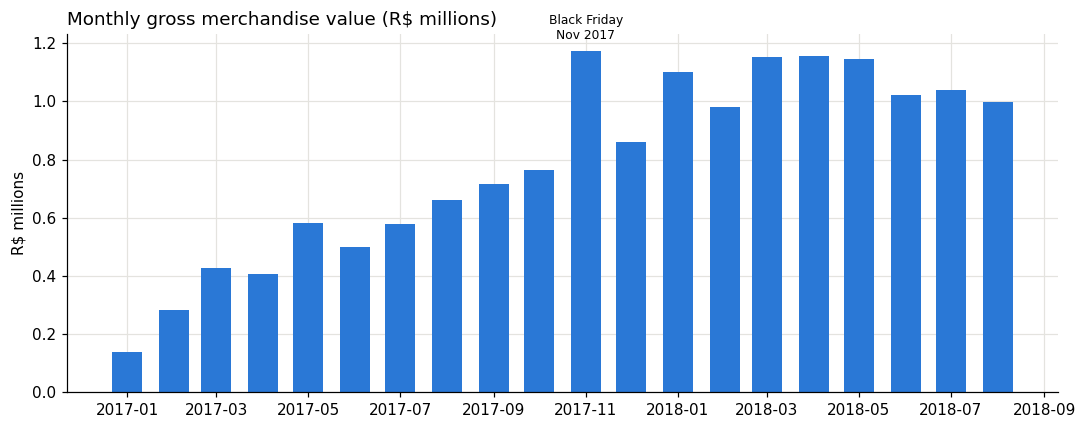

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
m = pd.to_datetime(kpis['month'])
ax.bar(m, kpis['gmv'] / 1e6, width=20, color=BLUE)
peak = kpis['gmv'].idxmax()
ax.annotate('Black Friday\nNov 2017', (m[10], kpis['gmv'][10] / 1e6), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8)
ax.set_title('Monthly gross merchandise value (R$ millions)'); ax.set_ylabel('R$ millions')
save(fig, '01_gmv.png')

Growth is almost entirely **new customers**: returning customers place only a few percent of orders. That makes
the next question central.

## 2. Do customers come back?

In [6]:
print(sql("select avg(is_repeat::int) as repeat_rate, count(*) as customers from dim_customers"))
print(Path('sql/02_marts/04_mart_cohort_retention.sql').read_text())

   repeat_rate  customers
0         0.03      94990
-- Monthly acquisition cohorts: share of each cohort ordering again N months after their first order.
with first_orders as (
    select customer_unique_id, date_trunc('month', first_order_at)::date as cohort
    from dim_customers
),
activity as (
    select distinct f.customer_unique_id, fo.cohort,
           date_diff('month', fo.cohort, f.purchase_month) as months_since
    from fct_orders f
    join first_orders fo using (customer_unique_id)
    where f.is_valid
)
select
    cohort,
    months_since,
    count(*)                                                        as customers,
    count(*) / max(count(*)) over (partition by cohort)             as retention
from activity
where cohort between date '2017-01-01' and date '2018-08-01'
group by 1, 2
order by 1, 2



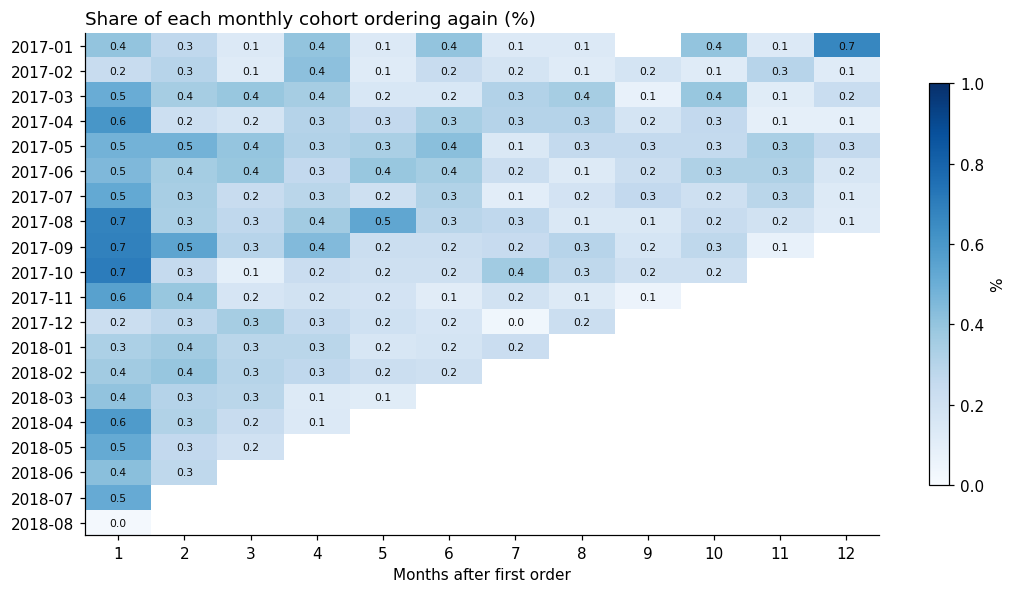

Average share ordering again in month 1: 0.46%


In [7]:
cohorts = sql('select * from mart_cohort_retention')
table = cohorts.pivot(index='cohort', columns='months_since', values='retention').loc[:, 1:12] * 100
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(table.values, cmap='Blues', aspect='auto', vmin=0, vmax=1.0)
ax.set_xticks(range(table.shape[1]), table.columns); ax.set_yticks(range(len(table)), [str(c)[:7] for c in table.index])
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=7, color=INK)
ax.set_xlabel('Months after first order'); ax.set_title('Share of each monthly cohort ordering again (%)'); ax.grid(False)
fig.colorbar(im, ax=ax, label='%', shrink=0.8)
save(fig, '02_cohort_retention.png')
print(f"Average share ordering again in month 1: {table[1].mean():.2f}%")

Fewer than 1% of customers order again in any given month after their first purchase, and about 3% ever do.
This is a **one-purchase marketplace**: classic retention tactics have a low ceiling.

## 3. Customer segments (RFM)

In [8]:
rfm = sql('''select segment, count(*) as customers, avg(monetary) as avg_spend, sum(monetary) as total_spend,
                    avg(recency_days) as avg_recency_days from mart_rfm group by 1 order by total_spend desc''')
rfm['share_of_customers_%'] = rfm['customers'] / rfm['customers'].sum() * 100
rfm['share_of_spend_%'] = rfm['total_spend'] / rfm['total_spend'].sum() * 100
rfm

,segment,customers,avg_spend,total_spend,avg_recency_days,share_of_customers_%,share_of_spend_%
0,"Lapsed, high value",21056,299.468,6.304e+06,386.440,22.167,40.059
1,"New, high value",14645,303.100,4.439e+06,141.683,15.417,28.209
2,"Lapsed, low value",34287,72.535,2.487e+06,388.069,36.095,15.805
3,"New, low value",22114,73.068,1.616e+06,139.686,23.280,10.269
4,"Loyal, lapsing",1651,298.144,4.922e+05,370.959,1.738,3.128
5,"Loyal, active",1237,321.764,3.980e+05,138.479,1.302,2.529


With 97% one-time buyers, frequency barely varies, so segments mostly split customers by recency and spend.
The "Loyal" segments are small but spend about the same per customer as high-value one-time buyers.

## 4. How much does late delivery hurt satisfaction?

`late` = delivered after the date promised at purchase (dates compared, so delivery *on* the promised day is on time).

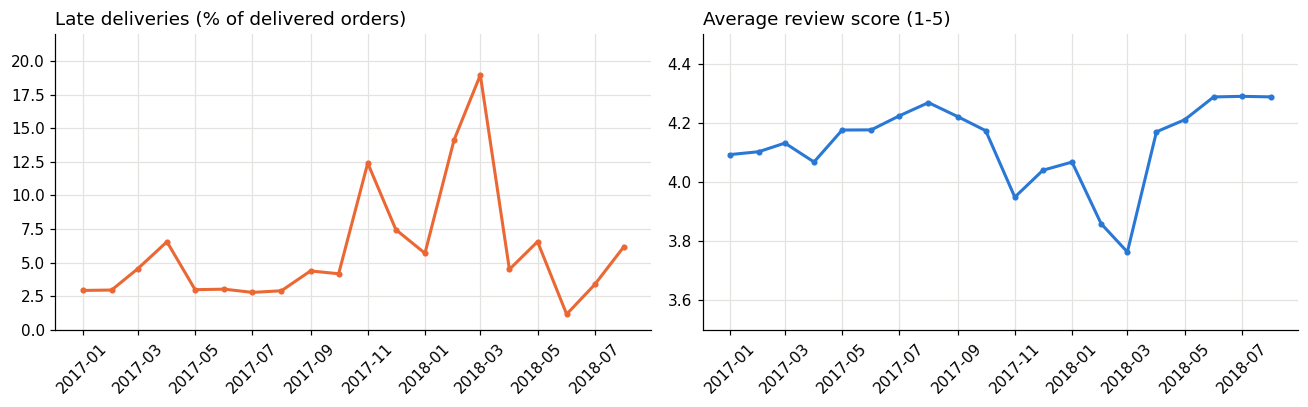

Correlation of monthly late rate and average review: -0.87


In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8))
a.plot(m, kpis['late_rate'] * 100, color=ORANGE, lw=2, marker='o', ms=3)
a.set_title('Late deliveries (% of delivered orders)'); a.set_ylim(0, 22)
b.plot(m, kpis['avg_review'], color=BLUE, lw=2, marker='o', ms=3)
b.set_title('Average review score (1-5)'); b.set_ylim(3.5, 4.5)
for ax in (a, b):
    ax.tick_params(axis='x', labelrotation=45)
save(fig, '03_late_vs_reviews_monthly.png')
print(f"Correlation of monthly late rate and average review: {kpis['late_rate'].corr(kpis['avg_review']):.2f}")

In [10]:
orders = analysis.delivered_reviewed_orders(con)
effect = analysis.late_review_effect(orders)
effect

,effect_stars,ci_low,ci_high,orders
model,,,,
Raw difference,-2.020,-2.059,-1.981,95560
With controls,-1.973,-2.013,-1.933,95560


Controlling for category, customer state, month, order value, freight share and the number of items and sellers barely
changes the estimate: a late delivery costs about **two stars**, and it isn't explained by *which* orders tend to run late.

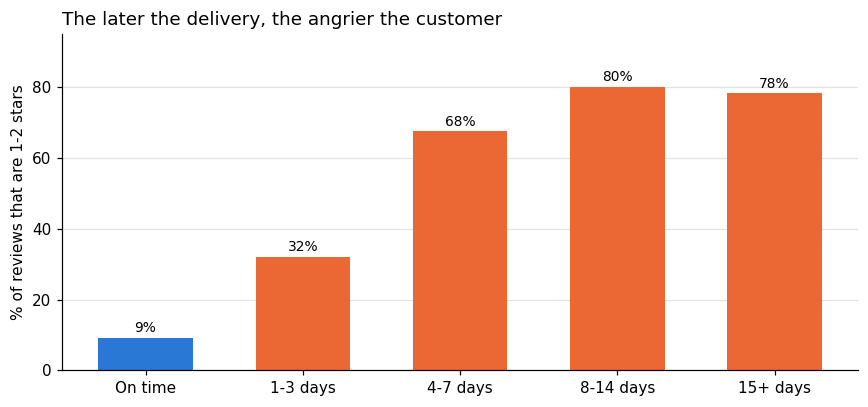

,orders,avg_review,low_review_share
days_late,,,
On time,89182,4.291,0.092
1-3 days,1851,3.291,0.321
4-7 days,1748,2.105,0.676
8-14 days,1446,1.671,0.802
15+ days,1333,1.724,0.783


In [11]:
dose = analysis.lateness_dose_response(orders)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(dose.index.astype(str), dose['low_review_share'] * 100, color=[BLUE] + [ORANGE] * 4, width=0.6)
for i, v in enumerate(dose['low_review_share'] * 100):
    ax.text(i, v + 1.5, f'{v:.0f}%', ha='center', fontsize=9)
ax.set_ylabel('% of reviews that are 1-2 stars'); ax.set_ylim(0, 95)
ax.set_title('The later the delivery, the angrier the customer'); ax.grid(axis='x', visible=False)
save(fig, '04_dose_response.png')
dose

## 5. Where does lateness happen?

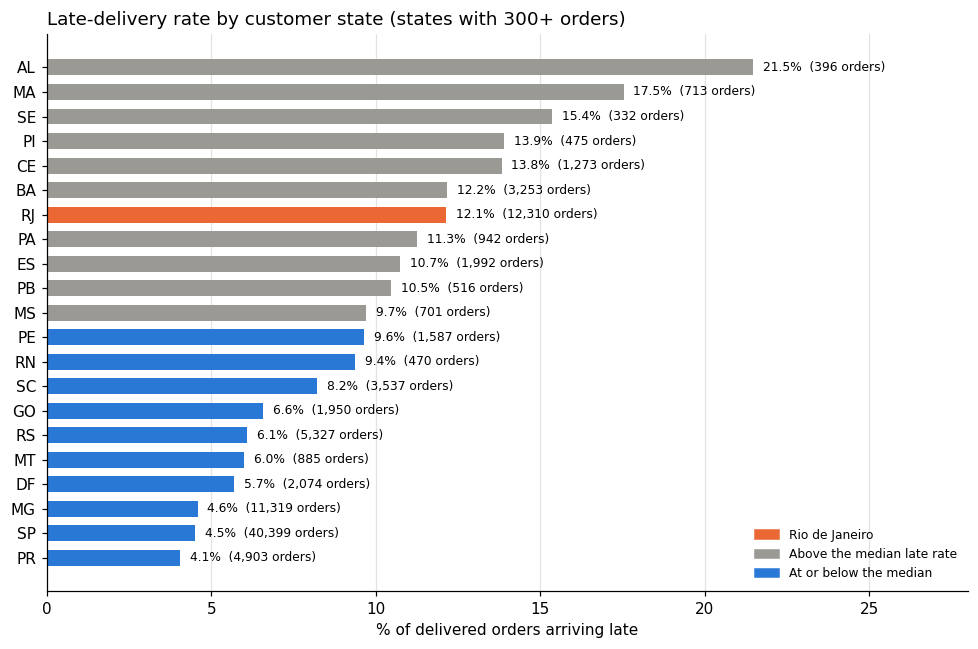

,state,orders,late_rate,median_delivery_days,median_promised_days,median_distance_km,avg_review
0,AL,396,0.215,22.0,32.0,1914.982,3.847
1,MA,713,0.175,19.0,31.0,2196.831,3.829
2,SE,332,0.154,18.0,30.0,1721.030,3.900
3,PI,475,0.139,16.0,30.0,2053.868,3.994
4,CE,1273,0.138,18.0,32.0,2292.467,3.940
5,BA,3253,0.122,17.0,30.0,1422.786,3.929
6,RJ,12310,0.121,12.0,25.0,394.279,3.965
7,PA,942,0.113,21.0,37.0,2392.933,3.913
8,ES,1992,0.107,14.0,26.0,761.996,4.079
9,PB,516,0.105,18.0,33.0,2161.478,4.074


In [12]:
states = sql('select * from mart_delivery_by_state where orders >= 300 order by late_rate desc')
fig, ax = plt.subplots(figsize=(9, 6))
colors = [ORANGE if s in ('RJ',) else (BLUE if r < states['late_rate'].median() else GREY) for s, r in zip(states['state'], states['late_rate'], strict=True)]
ax.barh(states['state'][::-1], states['late_rate'][::-1] * 100, color=colors[::-1], height=0.65)
for y, (r, n) in enumerate(zip(states['late_rate'][::-1] * 100, states['orders'][::-1], strict=True)):
    ax.text(r + 0.3, y, f'{r:.1f}%  ({n:,} orders)', va='center', fontsize=8)
ax.set_xlabel('% of delivered orders arriving late'); ax.set_xlim(0, 28)
ax.set_title('Late-delivery rate by customer state (states with 300+ orders)'); ax.grid(axis='y', visible=False)
from matplotlib.patches import Patch

ax.legend(handles=[Patch(color=ORANGE, label='Rio de Janeiro'), Patch(color=GREY, label='Above the median late rate'),
                   Patch(color=BLUE, label='At or below the median')], frameon=False, loc='lower right', fontsize=8)
save(fig, '05_late_by_state.png')
states[['state', 'orders', 'late_rate', 'median_delivery_days', 'median_promised_days', 'median_distance_km', 'avg_review']]

In [13]:
rj, sp = states.set_index('state').loc['RJ'], states.set_index('state').loc['SP']
print(f"Rio de Janeiro: {rj['orders']:,.0f} orders, {rj['late_rate']:.1%} late, median {rj['median_distance_km']:.0f} km from the seller")
print(f"Sao Paulo:      {sp['orders']:,.0f} orders, {sp['late_rate']:.1%} late, median {sp['median_distance_km']:.0f} km")
late_avoided = rj['orders'] * (rj['late_rate'] - sp['late_rate'])
print(f"If Rio matched Sao Paulo's late rate: about {late_avoided:,.0f} fewer late orders over the period, "
      f"each worth about {abs(effect.loc['With controls', 'effect_stars']):.1f} review stars")

Rio de Janeiro: 12,310 orders, 12.1% late, median 394 km from the seller
Sao Paulo:      40,399 orders, 4.5% late, median 163 km
If Rio matched Sao Paulo's late rate: about 941 fewer late orders over the period, each worth about 2.0 review stars


Lateness is worst in the far north-east, which is expected given the distances, but **Rio de Janeiro** stands out:
the second-largest market, close to most sellers, yet late 2.7 times as often as São Paulo. That
points to last-mile or carrier performance in Rio rather than distance.

## 6. Retention or first-order experience?

In [14]:
first = analysis.first_orders_with_followup(con, days=180)
late_repeat = analysis.repeat_after_late(first)
print(f"Customers with 180 days of follow-up: {late_repeat['customers']:,}")
print(f"Ordered again within 180 days: {late_repeat['repeat_rate_on_time']:.2%} after an on-time first delivery, "
      f"{late_repeat['repeat_rate_late']:.2%} after a late one")
print(f"Adjusted odds ratio {late_repeat['odds_ratio']:.2f} (95% CI {late_repeat['ci_low']:.2f}-{late_repeat['ci_high']:.2f}), "
      f"p = {late_repeat['p_value']:.2f}")

Customers with 180 days of follow-up: 56,247
Ordered again within 180 days: 3.19% after an on-time first delivery, 2.77% after a late one
Adjusted odds ratio 0.90 (95% CI 0.74-1.10), p = 0.30


The direction is what you'd expect (fewer late customers return), but with repeats this rare the difference is not
statistically distinguishable from zero. An earlier version of this analysis reported a significant effect; it came
from a model that hadn't converged and from customers having unequal time to return, both fixed here.

In [15]:
propensity = analysis.repeat_propensity_model(first)
print(f"Trained on {propensity['train_customers']:,} customers, tested on {propensity['test_customers']:,} acquired later")
print(f"AUC {propensity['auc']:.3f}; repeat rate in the top-scored 10% {propensity['top_decile_repeat_rate']:.1%} "
      f"vs {propensity['base_rate']:.1%} overall ({propensity['top_decile_lift']:.1f}x)")

Trained on 21,227 customers, tested on 35,020 acquired later
AUC 0.589; repeat rate in the top-scored 10% 5.4% vs 3.0% overall (1.8x)


First-order information identifies likely repeat buyers only weakly. Combined with a 3% repeat rate, a customer's
lifetime value is, for practical purposes, **the value of their first order**: a full lifetime-value model (e.g. BG/NBD)
has almost nothing to learn from here.

## 7. Findings and recommendations

1. **Growth is acquisition-driven.** GMV grew strongly year on year (Jan-Aug), and only a few percent of orders come
   from returning customers; about 3% of customers ever buy twice.
2. **Late delivery costs about two review stars**, robust to controls; 1-3 days late already more than triples the share
   of 1-2 star reviews, and 4-7 days late makes most reviews negative.
3. **Lateness is concentrated:** the far north-east, and Rio de Janeiro despite short distances. Lateness spiked after
   Black Friday 2017 and in February-March 2018, when average reviews fell to their lowest.
4. **Retention has a low ceiling:** repeat buying is rare, weakly predictable, and not measurably moved by a late
   first delivery.

**Recommendations**
- **Invest in the first-order experience, not retention campaigns.** Reviews drive marketplace reputation and
  conversion of *new* customers, which is where growth comes from.
- **Fix Rio de Janeiro first:** the biggest gap between expected and actual performance, in the second-largest market.
- **Plan carrier capacity for peaks** (Black Friday, post-holiday): the late rate at least doubled after both.
- **Use regional delivery promises** in the north-east, and track late rate by state as a weekly KPI.
- **Use the propensity model only for cheap targeting** (e.g. which first-time buyers get a follow-up offer); don't
  build retention strategy on it.

**Limitations.** Observational data: the late-delivery effect is controlled, not experimental (an A/B test of delivery
promises would settle it). Reviews are only left by some customers. Data ends August 2018.